# 1. Input

In [39]:
from pathlib import Path

# Đường dẫn thư mục gốc dự án
# UPDATED: Chỉ sửa BASE_DIR nếu thư mục dự án của em nằm ở vị trí khác.
BASE_DIR = Path(r"D:\EdgeAI\warm-up")

# Đường dẫn thư mục data
DATA_DIR = BASE_DIR / "data"

# Đường dẫn train, test
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

# Đường dẫn ảnh và nhãn
TRAIN_IMAGES = TRAIN_DIR / "images"
TRAIN_LABELS = TRAIN_DIR / "labels"

# Đường dẫn dữ liệu TextCNN
INTENT_TRAIN = DATA_DIR / "intent_train.csv"
INTENT_TEST = DATA_DIR / "intent_test.csv"

# Kiểm tra đường dẫn
print("Data:", DATA_DIR.exists())
print("Train:", TRAIN_DIR.exists())
print("Test:", TEST_DIR.exists())
print("Train Images:", TRAIN_IMAGES.exists())
print("Train Labels:", TRAIN_LABELS.exists())
print("Intent Train:", INTENT_TRAIN.exists())
print("Intent Test:", INTENT_TEST.exists())

Data: True
Train: True
Test: True
Train Images: True
Train Labels: True
Intent Train: True
Intent Test: True


In [40]:
import pandas as pd
from pathlib import Path

root = Path(r"D:\EdgeAI\warm-up\data")

train = pd.read_csv(root / "intent_train.csv")
test  = pd.read_csv(root / "intent_test.csv")
sub   = pd.read_csv(root / "sample_submission.csv")

train_imgs = sorted((root / "train/images").glob("*.png"))
train_lbls = sorted((root / "train/labels").glob("*.txt"))
test_imgs  = sorted((root / "test/images").glob("*.png"))

print(len(train_imgs), len(train_lbls), len(test_imgs))

img_ids = {p.stem for p in train_imgs}
lbl_ids = {p.stem for p in train_lbls}
print("Ảnh thiếu label:", len(img_ids - lbl_ids))
print("Label thiếu ảnh:", len(lbl_ids - img_ids))

140 140 60
Ảnh thiếu label: 0
Label thiếu ảnh: 0


In [41]:
print(train.shape, test.shape, sub.shape)
print(train.head())
print(test.head())
print(sub.head())

(63, 3) (28, 2) (88, 3)
  question_id                                           question    intent
0     tq_0001  Bien canh bao nguoi di bo qua duong nam o ben ...  LOCATION
1     tq_0002           Ban co nhin thay xe tai trong anh khong?     EXIST
2     tq_0003      Vach qua duong co xuat hien trong canh khong?     EXIST
3     tq_0004  Trong anh co tat ca bao nhieu bien canh bao ng...     COUNT
4     tq_0005  Hay xac dinh xe dap nam ben trai, o giua hay b...  LOCATION
  question_id                                           question
0      q_0001  Dem so loai doi tuong giao thong khac nhau tro...
1      q_0002      Trong anh co tat ca bao nhieu den giao thong?
2      q_0003  Hay dem so bien canh bao nguoi di bo qua duong...
3      q_0004  Hay xac dinh xe tai nam ben trai, o giua hay b...
4      q_0005    Hay dem so den giao thong xuat hien trong canh.
   task_type sample_id                                         prediction
0  DETECTION  img_0001  [{"class_id":0,"score":0.5,"bbox":[40.

(1672, 941) RGB


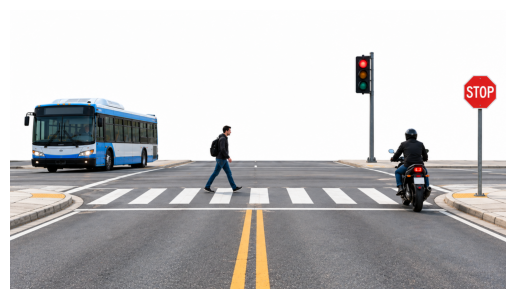

In [42]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(train_imgs[0])
print(img.size, img.mode)
plt.imshow(img); plt.axis("off"); plt.show()

# 2. Doc danh sach class 

In [43]:
with open(root / "classes.txt", encoding="utf-8") as f:
    classes = [line.strip() for line in f if line.strip()]

print("Số lớp:", len(classes))
print(classes)

Số lớp: 10
['person', 'bicycle', 'motorcycle', 'car', 'bus', 'truck', 'traffic_light', 'stop_sign', 'crossing_warning_sign', 'zebra_crossing']


In [44]:
id2name = {i: name for i, name in enumerate(classes)}
name2id = {name: i for i, name in enumerate(classes)}

print(id2name)

{0: 'person', 1: 'bicycle', 2: 'motorcycle', 3: 'car', 4: 'bus', 5: 'truck', 6: 'traffic_light', 7: 'stop_sign', 8: 'crossing_warning_sign', 9: 'zebra_crossing'}


In [45]:
import numpy as np

all_ids = []
for p in train_lbls:
    arr = np.loadtxt(p, ndmin=2)
    if arr.size:                      # bỏ qua file label rỗng
        all_ids.extend(arr[:, 0].astype(int))

all_ids = np.array(all_ids)
print("id nhỏ nhất / lớn nhất:", all_ids.min(), all_ids.max())

# đếm số box mỗi lớp
from collections import Counter
cnt = Counter(all_ids)
for i in sorted(cnt):
    print(f"{i:3d} {id2name[i]:20s} {cnt[i]}")

id nhỏ nhất / lớn nhất: 0 9
  0 person               161
  1 bicycle              64
  2 motorcycle           48
  3 car                  92
  4 bus                  58
  5 truck                50
  6 traffic_light        70
  7 stop_sign            50
  8 crossing_warning_sign 53
  9 zebra_crossing       82


# 3. Check dataset 

check 3 file csv 

In [46]:
print(train.shape, test.shape, sub.shape)
display(train.head())
display(test.head())
display(sub.head())

print("Giá trị thiếu (train):\n", train.isnull().sum())
print("Dòng trùng (train):", train.duplicated().sum())
print("Cột train:", train.columns.tolist())
print("Cột test :", test.columns.tolist())
print("Cột sub  :", sub.columns.tolist())

(63, 3) (28, 2) (88, 3)


,question_id,question,intent
0,tq_0001,Bien canh bao nguoi di bo qua duong nam o ben ...,LOCATION
1,tq_0002,Ban co nhin thay xe tai trong anh khong?,EXIST
2,tq_0003,Vach qua duong co xuat hien trong canh khong?,EXIST
3,tq_0004,Trong anh co tat ca bao nhieu bien canh bao ng...,COUNT
4,tq_0005,"Hay xac dinh xe dap nam ben trai, o giua hay b...",LOCATION


,question_id,question
0,q_0001,Dem so loai doi tuong giao thong khac nhau tro...
1,q_0002,Trong anh co tat ca bao nhieu den giao thong?
2,q_0003,Hay dem so bien canh bao nguoi di bo qua duong...
3,q_0004,"Hay xac dinh xe tai nam ben trai, o giua hay b..."
4,q_0005,Hay dem so den giao thong xuat hien trong canh.


,task_type,sample_id,prediction
0,DETECTION,img_0001,"[{""class_id"":0,""score"":0.5,""bbox"":[40.0,60.0,1..."
1,DETECTION,img_0002,"[{""class_id"":0,""score"":0.5,""bbox"":[40.0,60.0,1..."
2,DETECTION,img_0003,[]
3,DETECTION,img_0004,"[{""class_id"":0,""score"":0.5,""bbox"":[40.0,60.0,1..."
4,DETECTION,img_0005,"[{""class_id"":0,""score"":0.5,""bbox"":[40.0,60.0,1..."


Giá trị thiếu (train):
 question_id    0
question       0
intent         0
dtype: int64
Dòng trùng (train): 0
Cột train: ['question_id', 'question', 'intent']
Cột test : ['question_id', 'question']
Cột sub  : ['task_type', 'sample_id', 'prediction']


check 3 file label 

In [47]:
import numpy as np

bad = []
empty = []
n_boxes = {}

for p in train_lbls:
    lines = [l.split() for l in open(p) if l.strip()]
    if not lines:
        empty.append(p.stem)
        continue
    n_boxes[p.stem] = len(lines)
    for parts in lines:
        if len(parts) != 5:
            bad.append((p.stem, "sai số cột", parts)); continue
        c, x, y, w, h = int(parts[0]), *map(float, parts[1:])
        if not (0 <= c < len(classes)):
            bad.append((p.stem, "class_id ngoài khoảng", c))
        if not all(0 <= v <= 1 for v in (x, y, w, h)):
            bad.append((p.stem, "toạ độ ngoài [0,1]", (x, y, w, h)))
        if w <= 0 or h <= 0:
            bad.append((p.stem, "box rỗng", (w, h)))

print("File label rỗng:", len(empty))
print("Dòng lỗi:", len(bad))
for b in bad[:10]:
    print(b)
print("Số box/ảnh:", pd.Series(n_boxes).describe())

File label rỗng: 0
Dòng lỗi: 0
Số box/ảnh: count    140.000000
mean       5.200000
std        2.714735
min        1.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       12.000000
dtype: float64


check img 

In [48]:
from PIL import Image
from collections import Counter

sizes, modes, corrupt = Counter(), Counter(), []

for p in train_imgs + test_imgs:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            sizes[im.size] += 1
            modes[im.mode] += 1
    except Exception as e:
        corrupt.append((p.name, str(e)))

print("Ảnh hỏng:", len(corrupt), corrupt[:5])
print("Kích thước:", sizes.most_common(5))
print("Mode:", modes)

Ảnh hỏng: 0 []
Kích thước: [((1672, 941), 178), ((1672, 940), 7), ((1671, 941), 6), ((1774, 887), 5), ((1536, 1024), 2)]
Mode: Counter({'RGB': 200})


check img + label 

In [49]:
test_ids = [p.stem for p in test_imgs]
print("Ví dụ id test:", test_ids[:9])
print("Số ảnh test:", len(test_ids), "| số dòng sub:", len(sub))

Ví dụ id test: ['img_0001', 'img_0002', 'img_0003', 'img_0004', 'img_0005', 'img_0006', 'img_0007', 'img_0008', 'img_0009']
Số ảnh test: 60 | số dòng sub: 88


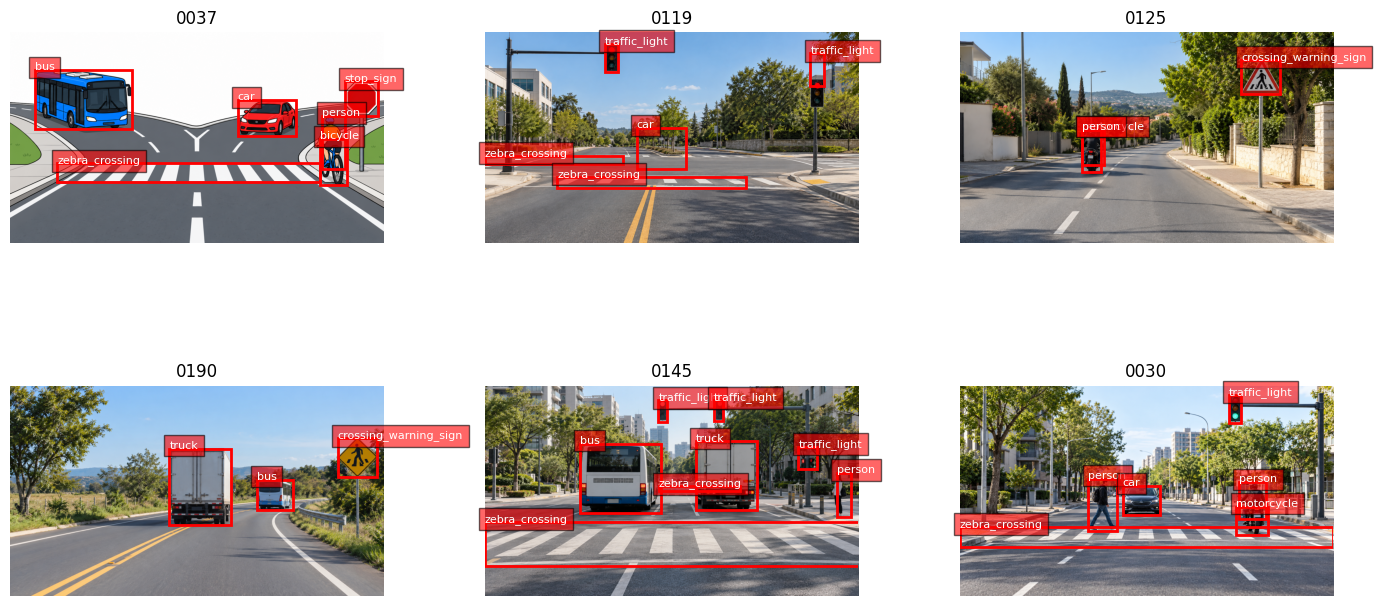

In [50]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def show(idx, ax):
    p = train_imgs[idx]
    img = Image.open(p)
    W, H = img.size
    ax.imshow(img); ax.axis("off"); ax.set_title(p.stem)
    lbl = root / "train/labels" / f"{p.stem}.txt"
    for line in open(lbl):
        c, x, y, w, h = map(float, line.split())
        ax.add_patch(patches.Rectangle(((x-w/2)*W, (y-h/2)*H), w*W, h*H,
                                       fill=False, edgecolor="red", lw=2))
        ax.text((x-w/2)*W, (y-h/2)*H, classes[int(c)], color="white",
                bbox=dict(facecolor="red", alpha=0.6), fontsize=8)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, i in zip(axes.ravel(), np.random.choice(len(train_imgs), 6, replace=False)):
    show(i, ax)
plt.tight_layout(); plt.show()

# 4. Check YOLO

In [51]:
import numpy as np
import pandas as pd
from collections import Counter

with open(root / "classes.txt", encoding="utf-8") as f:
    classes = [l.strip() for l in f if l.strip()]
nc = len(classes)

rows, errors, empty = [], [], []

for p in train_lbls:
    lines = [l.strip() for l in open(p) if l.strip()]
    if not lines:
        empty.append(p.stem)
        continue
    for ln, line in enumerate(lines, 1):
        parts = line.split()
        if len(parts) != 5:
            errors.append((p.stem, ln, "sai số cột", len(parts)))
            continue
        try:
            c = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:])
        except ValueError:
            errors.append((p.stem, ln, "không phải số", line))
            continue
        if not (0 <= c < nc):
            errors.append((p.stem, ln, "class_id ngoài khoảng", c))
        if not (0 <= x <= 1 and 0 <= y <= 1):
            errors.append((p.stem, ln, "tâm ngoài [0,1]", (x, y)))
        if not (0 < w <= 1 and 0 < h <= 1):
            errors.append((p.stem, ln, "w/h không hợp lệ", (w, h)))
        if x - w/2 < -1e-3 or x + w/2 > 1 + 1e-3 or y - h/2 < -1e-3 or y + h/2 > 1 + 1e-3:
            errors.append((p.stem, ln, "box tràn ra ngoài ảnh", (x, y, w, h)))
        rows.append([p.stem, c, x, y, w, h])

df = pd.DataFrame(rows, columns=["id", "cls", "x", "y", "w", "h"])
df["name"] = df["cls"].map(lambda i: classes[i] if 0 <= i < nc else "?")
df["area"] = df["w"] * df["h"]

print("Số lớp:", nc)
print("Tổng số box:", len(df), "| số ảnh có box:", df["id"].nunique())
print("File label rỗng:", len(empty), empty[:5])
print("Số dòng lỗi:", len(errors))
for e in errors[:10]:
    print("  ", e)

Số lớp: 10
Tổng số box: 728 | số ảnh có box: 140
File label rỗng: 0 []
Số dòng lỗi: 0


In [52]:
dup = df.duplicated(subset=["id", "cls", "x", "y", "w", "h"]).sum()
print("Box trùng hệt nhau:", dup)

Box trùng hệt nhau: 0


name
person                   161
car                       92
zebra_crossing            82
traffic_light             70
bicycle                   64
bus                       58
crossing_warning_sign     53
stop_sign                 50
truck                     50
motorcycle                48
Name: count, dtype: int64


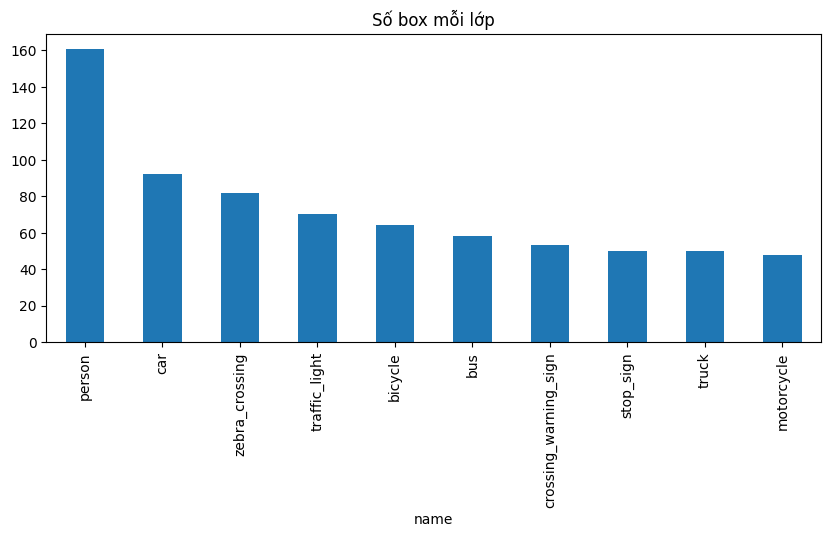

Lớp không có box nào: []


In [53]:
cnt = df["name"].value_counts()
print(cnt)

import matplotlib.pyplot as plt
cnt.plot(kind="bar", figsize=(10, 4), title="Số box mỗi lớp")
plt.show()

print("Lớp không có box nào:", [c for c in classes if c not in set(df["name"])])

In [54]:
print(df.groupby("id").size().describe())      # số object mỗi ảnh
print(df[["w", "h", "area"]].describe())        # kích thước box (chuẩn hoá)

print("Box rất nhỏ (area < 0.001):", (df["area"] < 0.001).sum())

count    140.000000
mean       5.200000
std        2.714735
min        1.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       12.000000
dtype: float64
                w           h        area
count  728.000000  728.000000  728.000000
mean     0.174231    0.184465    0.028882
std      0.236455    0.087598    0.031694
min      0.008971    0.024442    0.000276
25%      0.060407    0.124336    0.009541
50%      0.087919    0.173220    0.016160
75%      0.150419    0.244855    0.036501
max      1.000000    0.569607    0.210414
Box rất nhỏ (area < 0.001): 24


In [55]:
img_ids = {p.stem for p in train_imgs}
print("Ảnh không có dòng box nào:", len(img_ids - set(df["id"])))

Ảnh không có dòng box nào: 0


In [56]:
big = df[df["w"] > 0.5]
print(big)
print(big["name"].value_counts())

       id  cls         x         y         w         h            name  \
6    0001    9  0.503589  0.667375  0.735646  0.076514  zebra_crossing   
13   0002    9  0.529306  0.717322  0.892344  0.123273  zebra_crossing   
21   0003    9  0.510167  0.617960  0.809809  0.060574  zebra_crossing   
29   0005    9  0.277678  0.619022  0.555356  0.056323  zebra_crossing   
45   0009    9  0.546379  0.611052  0.579294  0.068013  zebra_crossing   
..    ...  ...       ...       ...       ...       ...             ...   
670  0171    9  0.479067  0.753454  0.832536  0.146652  zebra_crossing   
685  0175    9  0.500000  0.804463  1.000000  0.170032  zebra_crossing   
694  0179    9  0.394438  0.636026  0.788876  0.098831  zebra_crossing   
700  0187    9  0.495813  0.681190  0.869617  0.140276  zebra_crossing   
717  0195    9  0.508971  0.643464  0.833732  0.092455  zebra_crossing   

         area  
6    0.056287  
13   0.110002  
21   0.049053  
29   0.031279  
45   0.039400  
..        ...  

In [57]:
zc = df[df["name"] == "zebra_crossing"]
print(zc[["w", "h", "area"]].describe())
print("Box có w >= 0.99:", (zc["w"] >= 0.99).sum())

# xem có box nào tràn ra ngoài ảnh không
print("Lệch trái/phải:", ((zc["x"] - zc["w"]/2) < -1e-3).sum(), ((zc["x"] + zc["w"]/2) > 1 + 1e-3).sum())

               w          h       area
count  82.000000  82.000000  82.000000
mean    0.781201   0.097616   0.080743
std     0.220356   0.040225   0.045489
min     0.107656   0.024442   0.004004
25%     0.617867   0.069075   0.046533
50%     0.802931   0.091923   0.072935
75%     0.999402   0.118757   0.107703
max     1.000000   0.236982   0.210414
Box có w >= 0.99: 30
Lệch trái/phải: 0 0


In [58]:
print(df["name"].value_counts())
print("Số dòng lỗi:", len(errors), "| label rỗng:", len(empty))
print(Image.open(train_imgs[0]).size)

name
person                   161
car                       92
zebra_crossing            82
traffic_light             70
bicycle                   64
bus                       58
crossing_warning_sign     53
stop_sign                 50
truck                     50
motorcycle                48
Name: count, dtype: int64
Số dòng lỗi: 0 | label rỗng: 0
(1672, 941)


# 5. Truc quan hoa 

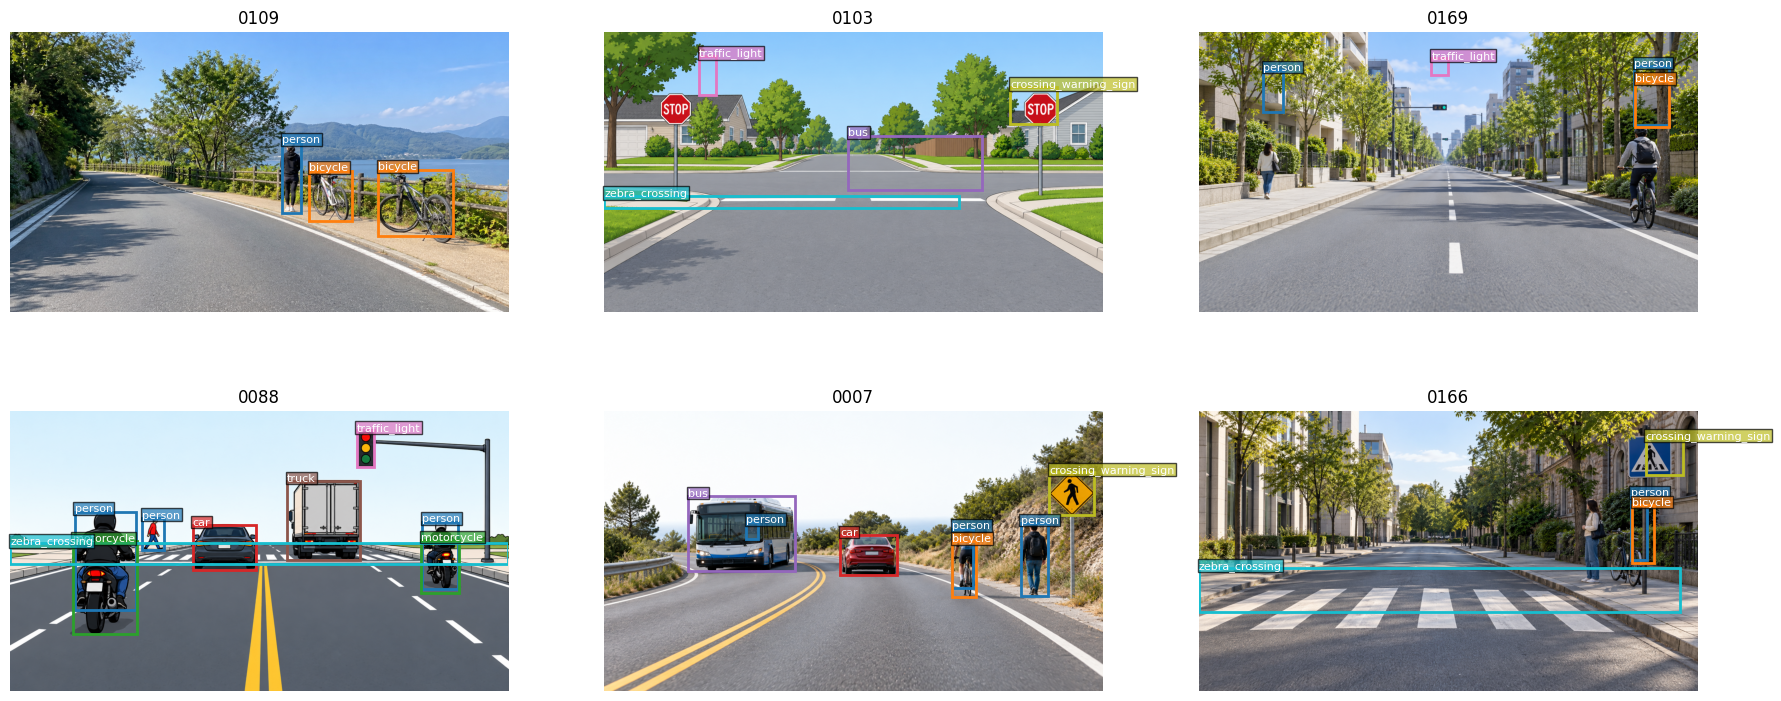

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

cmap = plt.get_cmap("tab10")
colors = {i: cmap(i) for i in range(len(classes))}

def show(idx, ax):
    p = train_imgs[idx]
    img = Image.open(p).convert("RGB")
    W, H = img.size
    ax.imshow(img); ax.axis("off"); ax.set_title(p.stem)
    for line in open(root / "train/labels" / f"{p.stem}.txt"):
        c, x, y, w, h = map(float, line.split())
        c = int(c)
        x1, y1 = (x - w/2) * W, (y - h/2) * H
        ax.add_patch(patches.Rectangle((x1, y1), w*W, h*H, fill=False,
                                       edgecolor=colors[c], lw=2))
        ax.text(x1, y1, classes[c], color="white", fontsize=8,
                bbox=dict(facecolor=colors[c], alpha=0.7, pad=1))

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, i in zip(axes.ravel(), np.random.choice(len(train_imgs), 6, replace=False)):
    show(i, ax)
plt.tight_layout(); plt.show()

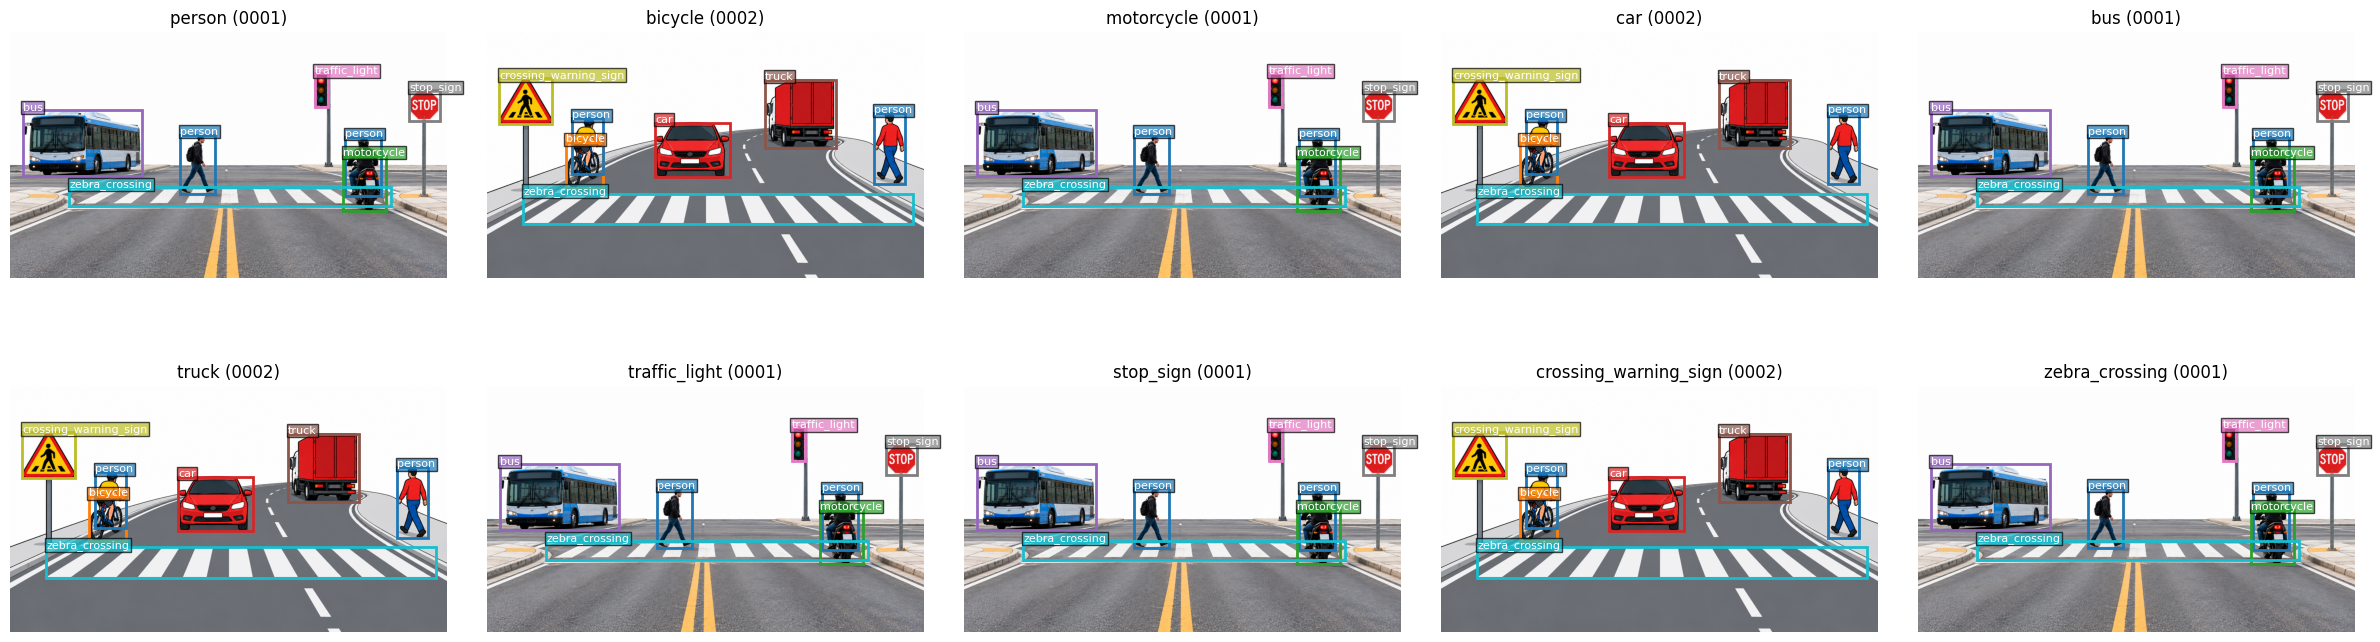

In [60]:
first_per_class = df.groupby("cls")["id"].first()
ids = {p.stem: i for i, p in enumerate(train_imgs)}

fig, axes = plt.subplots(2, 5, figsize=(24, 8))
for ax, (c, img_id) in zip(axes.ravel(), first_per_class.items()):
    show(ids[img_id], ax)
    ax.set_title(f"{classes[c]} ({img_id})")
plt.tight_layout(); plt.show()

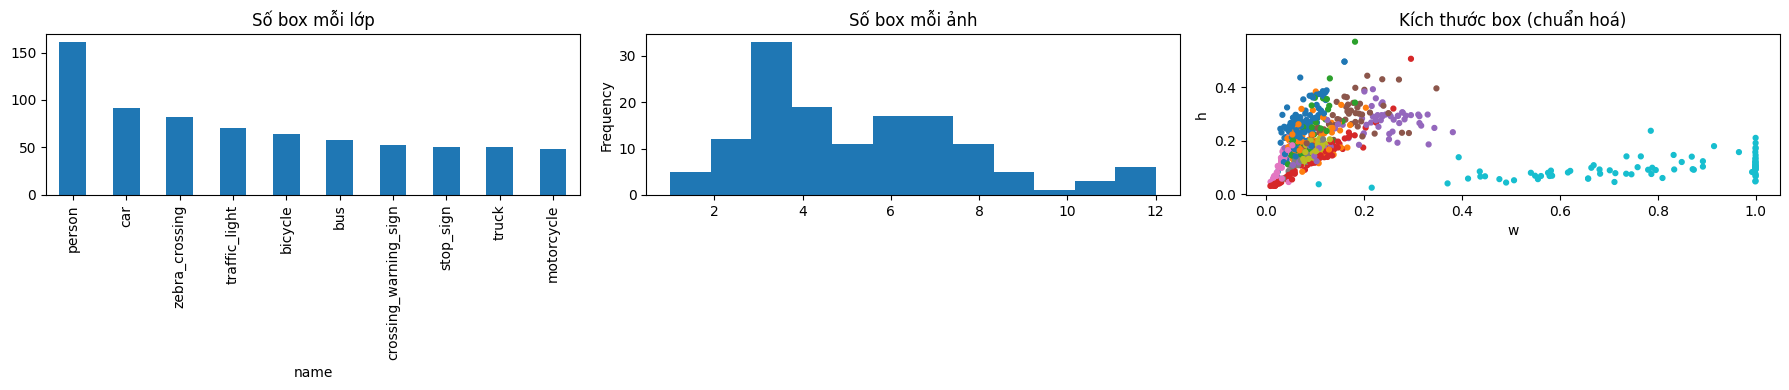

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

df["name"].value_counts().plot(kind="bar", ax=axes[0], title="Số box mỗi lớp")
df.groupby("id").size().plot(kind="hist", bins=12, ax=axes[1], title="Số box mỗi ảnh")
axes[2].scatter(df["w"], df["h"], c=df["cls"].map(lambda i: colors[i]), s=12)
axes[2].set_xlabel("w"); axes[2].set_ylabel("h"); axes[2].set_title("Kích thước box (chuẩn hoá)")

plt.tight_layout(); plt.show()

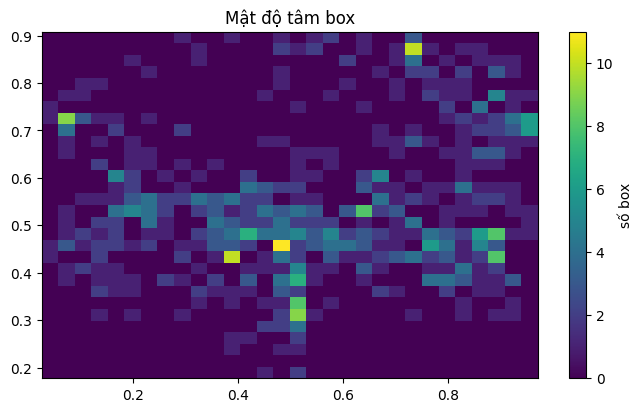

In [62]:
plt.figure(figsize=(8, 4.5))
plt.hist2d(df["x"], 1 - df["y"], bins=30, cmap="viridis")
plt.colorbar(label="số box"); plt.title("Mật độ tâm box"); plt.show()

# 6. Chia train/ val theo class

In [63]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

cls_count = df["cls"].value_counts()
img_cls = (df.groupby("id")["cls"]
             .apply(lambda s: min(set(s), key=lambda c: cls_count[c])))

ids = img_cls.index.to_numpy()
strat = img_cls.to_numpy()

# nhóm nào < 2 ảnh thì không stratify được -> đưa thẳng vào train
vc = pd.Series(strat).value_counts()
rare = set(vc[vc < 2].index)
mask = np.array([s in rare for s in strat])

ids_rare = ids[mask]
ids_ok, strat_ok = ids[~mask], strat[~mask]

train_ids, val_ids = train_test_split(
    ids_ok, test_size=0.2, random_state=42, stratify=strat_ok
)
train_ids = list(train_ids) + list(ids_rare)

no_box = sorted({p.stem for p in train_imgs} - set(ids))
train_ids = train_ids + no_box

print("Train:", len(train_ids), "| Val:", len(val_ids))
print("Ảnh của nhóm hiếm đưa vào train:", len(ids_rare))

Train: 112 | Val: 28
Ảnh của nhóm hiếm đưa vào train: 1


In [64]:
train_ids, val_ids = train_test_split(ids, test_size=0.2, random_state=42)

In [65]:
d_tr = df[df["id"].isin(train_ids)]["name"].value_counts()
d_va = df[df["id"].isin(val_ids)]["name"].value_counts()

check = pd.concat([d_tr, d_va], axis=1, keys=["train", "val"]).fillna(0).astype(int)
check["val_%"] = (check["val"] / (check["train"] + check["val"]) * 100).round(1)
print(check)

                       train  val  val_%
name                                    
person                   134   27   16.8
zebra_crossing            69   13   15.9
car                       66   26   28.3
bicycle                   56    8   12.5
traffic_light             53   17   24.3
bus                       46   12   20.7
stop_sign                 43    7   14.0
crossing_warning_sign     42   11   20.8
motorcycle                38   10   20.8
truck                     38   12   24.0


In [66]:
print(len(train_ids), len(val_ids))
print(len(set(train_ids) & set(val_ids)))   # phải bằng 0: không ảnh nào nằm ở cả hai tập

112 28
0


# 7. Cấu trúc YOLO

In [67]:

import shutil
from pathlib import Path

# Thư mục dataset đầu ra
out = root / "dataset"

if out.exists():
    shutil.rmtree(out)

# Tạo thư mục YOLO
for split in ["train", "val"]:
    (out / "images" / split).mkdir(parents=True)
    (out / "labels" / split).mkdir(parents=True)

# Ánh xạ ID ảnh với đường dẫn thực tế
img_map = {p.stem: p for p in train_imgs}

def put(ids, split):
    count = 0
    missing = 0

    for img_id in ids:
        img_id = str(img_id)

        # Lấy đường dẫn ảnh từ ID
        img_src = img_map.get(img_id)

        if img_src is None:
            print("Không tìm thấy ảnh:", img_id)
            continue

        # Copy ảnh
        img_dst = out / "images" / split / img_src.name
        shutil.copy2(img_src, img_dst)

        # Copy nhãn
        label_src = root / "train" / "labels" / f"{img_id}.txt"
        label_dst = out / "labels" / split / f"{img_id}.txt"

        if label_src.exists():
            shutil.copy2(label_src, label_dst)
        else:
            # Ảnh không có object
            label_dst.touch()
            missing += 1

        count += 1

    print(f"{split}: {count} ảnh | {missing} nhãn rỗng")

# Tạo train và validation
put(train_ids, "train")
put(val_ids, "val")

# Kiểm tra kết quả
for split in ["train", "val"]:
    imgs = list((out / "images" / split).glob("*.png"))
    labels = list((out / "labels" / split).glob("*.txt"))

    print(f"{split}: {len(imgs)} ảnh | {len(labels)} labels")

print("\nDataset đã tạo tại:", out.resolve())


train: 112 ảnh | 0 nhãn rỗng
val: 28 ảnh | 0 nhãn rỗng
train: 112 ảnh | 112 labels
val: 28 ảnh | 28 labels

Dataset đã tạo tại: D:\EdgeAI\warm-up\data\dataset


In [68]:
import yaml

data = {
    "path": str(out),
    "train": "images/train",
    "val": "images/val",
    "nc": len(classes),
    "names": {i: n for i, n in enumerate(classes)},
}
with open(out / "data.yaml", "w", encoding="utf-8") as f:
    yaml.dump(data, f, allow_unicode=True, sort_keys=False)

print(open(out / "data.yaml").read())

path: D:\EdgeAI\warm-up\data\dataset
train: images/train
val: images/val
nc: 10
names:
  0: person
  1: bicycle
  2: motorcycle
  3: car
  4: bus
  5: truck
  6: traffic_light
  7: stop_sign
  8: crossing_warning_sign
  9: zebra_crossing



In [69]:
for s in ["train", "val"]:
    ni = len(list((out / f"images/{s}").glob("*.png")))
    nl = len(list((out / f"labels/{s}").glob("*.txt")))
    print(s, ni, nl)

train 112 112
val 28 28


# 8. Huan luyen YOLO

In [72]:
!pip install -q ultralytics

from ultralytics import YOLO

# Khuyến nghị: Cần tự định nghĩa mô hình (custom yaml) để đạt số lượng tham số < 200.000
model = YOLO("yolo11n.pt") 

results = model.train(
    data=r"D:\EdgeAI\warm-up\data\dataset\data.yaml",
    imgsz=160,          # Đã sửa thành 160 theo khuyến nghị
    epochs=20,
    batch=8,
    patience=30,        
    seed=42,
    flipud=0.0,         
    degrees=0.0,        
    project=r"D:\EdgeAI\warm-up\notebook\runs",
    name="exp1",
)




[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


New https://pypi.org/project/ultralytics/8.4.203 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.198  Python-3.13.7 torch-2.15.0+cpu CPU (Intel Core i5-8250U 1.60GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\EdgeAI\warm-up\data\dataset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=160, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.p